# Predicting Player Retention/ Engagement

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
np.random.seed(42)

In [4]:
X = np.array([[0,0,1],
              [1,0,1],
              [1,1,1],
              [2,1,1],
              [2,2,1]])

y = np.array([0,1,2,3,4])
eta = .10
q = 2

W1 = np.random.randn(3,q)
W2 = np.random.randn(q,1)

In [5]:
def f(x):
    h = np.maximum(0, W1.T.dot(x))
    return W2.T.dot(h)

In [6]:
errors = []
epochs = 400
n = X.shape[0]
for epoch in range(epochs):
    dW2 = 0
    for i, j in enumerate(y):
        x = np.reshape(X[i], (3,1))
        h = np.maximum(0, W1.T.dot(x))
        dW2 += (2/n) * (f(x) - y[i])*h
  
    W2 = W2 - eta * dW2
    
    dW1 = 0
    for i, j in enumerate(y):
        x = np.reshape(X[i], (3,1))
        h = np.maximum(0, W1.T.dot(x))
        mat1 = np.heaviside(h, 0)

        dW1 += (2/n) * (f(x) - y[i]) * np.kron(x, (W2 * mat1).T)

    W1 = W1 - eta * dW1
    e = (1/n) * np.sum(np.square(f(X.T) - y))
    errors.append(e)

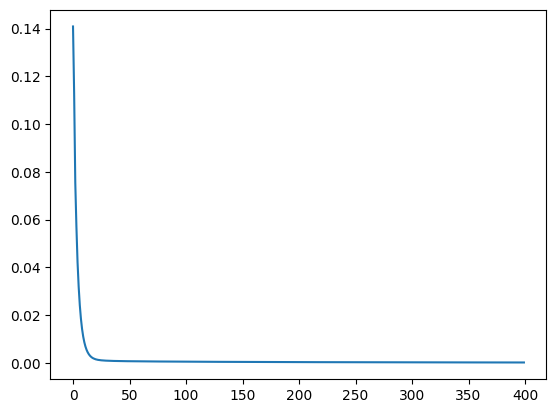

In [7]:
plt.plot(range(epochs), errors, label='line')
plt.show()